Carregando a base limpa

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../reports/figures", exist_ok=True)

df = pd.read_csv(
    "../data/processed/dublin_bikes_clean.csv",
    parse_dates=["last_reported"]
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3408656 entries, 0 to 3408655
Data columns (total 6 columns):
 #   Column               Dtype         
---  ------               -----         
 0   last_reported        datetime64[us]
 1   station_id           int64         
 2   num_bikes_available  int64         
 3   num_docks_available  int64         
 4   name                 str           
 5   address              str           
dtypes: datetime64[us](1), int64(3), str(2)
memory usage: 156.0 MB


Derivando hora e dia da semana do timestamp, e calculando ocupação como bikes sobre o total reportado na própria linha

In [2]:
df["hour"] = df["last_reported"].dt.hour
df["weekday"] = df["last_reported"].dt.dayofweek
df["total_docks"] = df["num_bikes_available"] + df["num_docks_available"]
df["occupancy"] = df["num_bikes_available"] / df["total_docks"]
df[["hour", "weekday", "total_docks", "occupancy"]].head()

,hour,weekday,total_docks,occupancy
0,0,3,31,0.774194
1,0,3,16,1.000000
2,0,3,30,0.166667
3,0,3,40,0.125000
4,0,3,40,0.500000


Ocupação média por hora do dia, groupby na hora e média da ocupação

In [3]:
occupancy_by_hour = df.groupby("hour")["occupancy"].mean()
occupancy_by_hour

hour
0     0.393459
1     0.393873
2     0.393438
3     0.393382
4     0.393464
5     0.387426
6     0.381629
7     0.367064
8     0.370305
9     0.383006
10    0.381911
11    0.379516
12    0.380710
13    0.381739
14    0.382855
15    0.380052
16    0.374075
17    0.377945
18    0.386445
19    0.392492
20    0.395533
21    0.395800
22    0.396066
23    0.394018
Name: occupancy, dtype: float64

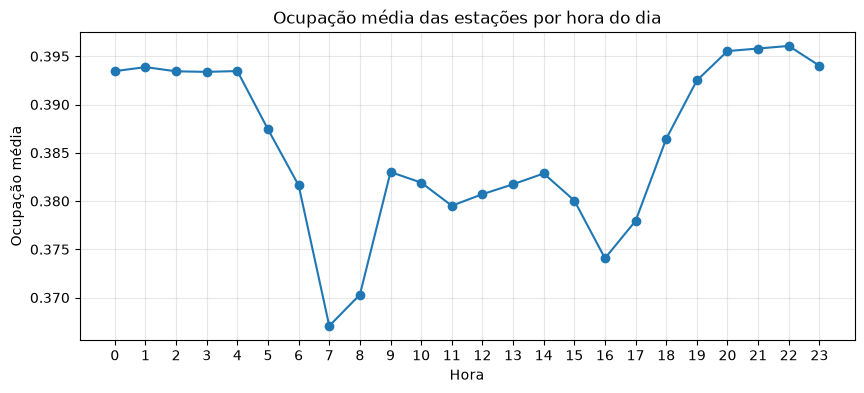

In [4]:
plt.figure(figsize=(10, 4))
plt.plot(occupancy_by_hour.index, occupancy_by_hour.values, marker="o", color="#1f77b4")
plt.title("Ocupação média das estações por hora do dia")
plt.xlabel("Hora")
plt.ylabel("Ocupação média")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.show()

Ocupação média por dia da semana, dayofweek devolve 0 a 6 começando na segunda

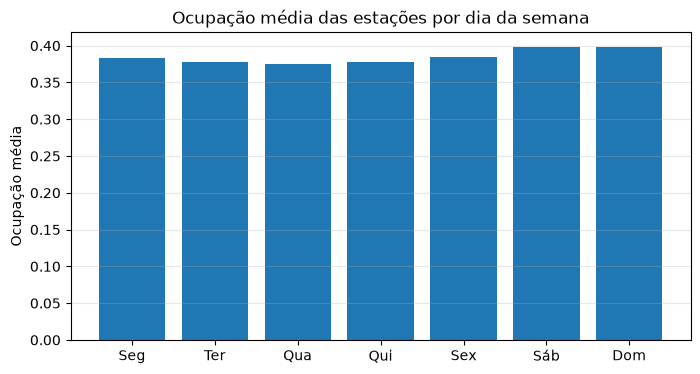

In [5]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
occupancy_by_weekday = df.groupby("weekday")["occupancy"].mean()

plt.figure(figsize=(8, 4))
plt.bar(dias, occupancy_by_weekday.values, color="#1f77b4")
plt.title("Ocupação média das estações por dia da semana")
plt.ylabel("Ocupação média")
plt.grid(axis="y", alpha=0.3)
plt.show()

Amplitude de cada estação, diferença entre a hora mais cheia e a mais vazia, estações com amplitude alta são as que mais variam ao longo do dia

In [6]:
occupancy_station_hour = df.groupby(["station_id", "hour"])["occupancy"].mean()
amplitude = occupancy_station_hour.groupby("station_id").max() - occupancy_station_hour.groupby("station_id").min()
amplitude.sort_values(ascending=False).head(10)

station_id
27     0.608150
115    0.598855
19     0.593272
114    0.591879
90     0.575785
112    0.565376
20     0.550090
100    0.547309
93     0.534347
26     0.529544
Name: occupancy, dtype: float64

Ocupação por hora das quatro estações de maior amplitude, com a média da cidade tracejada como referência, a linha cinza plana mostra por que a média esconde o comportamento individual

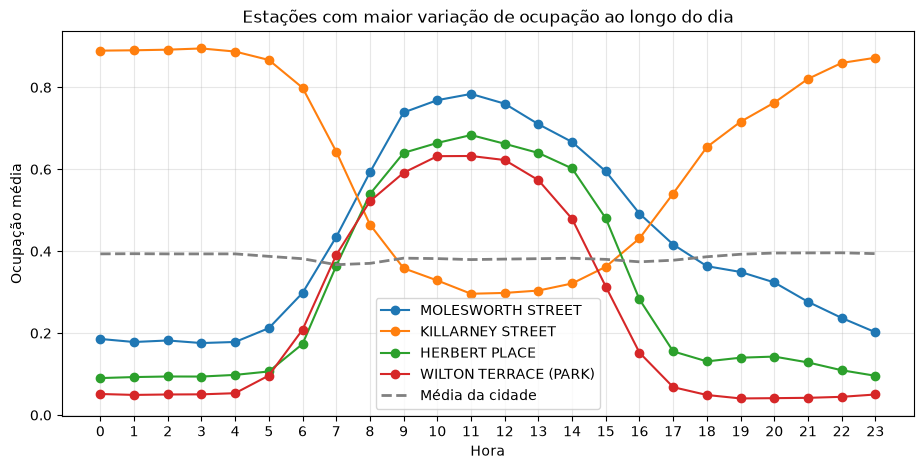

In [7]:
top_stations = amplitude.sort_values(ascending=False).head(4).index
nomes = df.groupby("station_id")["name"].last()

plt.figure(figsize=(11, 5))

for station in top_stations:
    serie = occupancy_station_hour.loc[station]
    plt.plot(serie.index, serie.values, marker="o", label=nomes[station])

plt.plot(
    occupancy_by_hour.index,
    occupancy_by_hour.values,
    color="gray",
    linestyle="--",
    linewidth=2,
    label="Média da cidade"
)

plt.title("Estações com maior variação de ocupação ao longo do dia")
plt.xlabel("Hora")
plt.ylabel("Ocupação média")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../reports/figures/occupancy_by_station_hour.png", dpi=150, bbox_inches="tight")
plt.show()

Resumo das estações de maior amplitude, com a hora de pico e a hora de vale de cada uma

In [8]:
resumo = pd.DataFrame({
    "name": nomes[top_stations],
    "amplitude": amplitude[top_stations].round(3),
    "hora_mais_cheia": occupancy_station_hour.loc[top_stations].groupby("station_id").idxmax().apply(lambda x: x[1]),
    "hora_mais_vazia": occupancy_station_hour.loc[top_stations].groupby("station_id").idxmin().apply(lambda x: x[1])
})
resumo

,name,amplitude,hora_mais_cheia,hora_mais_vazia
station_id,,,,
19,HERBERT PLACE,0.593,11,0
27,MOLESWORTH STREET,0.608,11,3
114,WILTON TERRACE (PARK),0.592,11,19
115,KILLARNEY STREET,0.599,3,11


## Conclusões

A ocupação média da cidade é praticamente constante ao longo do dia, variando apenas 3 pontos percentuais, porque bicicleta não desaparece do sistema, ela muda de lugar

O comportamento real aparece por estação, Killarney Street sai de 89% de ocupação às 4h para 29% às 11h, enquanto Molesworth Street faz o movimento inverso no mesmo intervalo, saindo de 18% para 78%

As curvas se cruzam às 7h e às 17h, que são os horários de deslocamento casa-trabalho, o que indica que a rede funciona como transporte de commute e não como lazer

Dia da semana tem efeito pequeno, fim de semana fica cerca de 2 pontos percentuais acima dos dias úteis

Operacionalmente, a redistribuição de bicicletas por caminhão deveria sair das estações de escritório no fim da tarde e abastecer as residenciais antes das 7h